In [141]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [142]:
import os
df = pd.read_csv('spam_email_dataset.csv')
df.head()

,email_id,subject,email_text,num_words,num_characters,num_exclamation_marks,num_links,has_suspicious_link,num_attachments,has_attachment,sender_email,sender_domain,sender_reputation_score,email_hour,email_day_of_week,is_weekend,num_recipients,contains_money_terms,contains_urgency_terms,label
0,0,Weekly Report,budget review - Statement our I claim world st...,19,114,0,2,0,2,1,lctvdzm@outlook.com,outlook.com,0.66,19,3,0,23,0,0,0
1,1,Project Update,team sync - President series today already. In...,18,114,0,7,0,0,0,pxyldmi@company.com,company.com,0.95,4,4,0,16,1,0,0
2,2,🔥WIN BIG NOW!!,win free urgent offer limited limited urgent u...,19,126,0,4,1,1,1,atvanls@unknownmail.cc,unknownmail.cc,0.68,3,0,0,10,1,1,1
3,3,🔥WIN BIG NOW!!,guarantee click now cash offer click now guara...,16,101,0,7,1,1,1,qalxcnf@chealdealz.xyz,chealdealz.xyz,0.69,19,5,1,25,1,1,1
4,4,Meeting Reminder,team sync - Significant property hotel not add...,18,111,0,7,1,2,1,xoiccxl@yahoo.com,yahoo.com,0.67,4,5,1,8,0,0,0


In [143]:
df.columns

Index(['email_id', 'subject', 'email_text', 'num_words', 'num_characters',
       'num_exclamation_marks', 'num_links', 'has_suspicious_link',
       'num_attachments', 'has_attachment', 'sender_email', 'sender_domain',
       'sender_reputation_score', 'email_hour', 'email_day_of_week',
       'is_weekend', 'num_recipients', 'contains_money_terms',
       'contains_urgency_terms', 'label'],
      dtype='object')

In [144]:
df.shape

(10000, 20)

In [145]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   email_id                 10000 non-null  int64  
 1   subject                  10000 non-null  object 
 2   email_text               10000 non-null  object 
 3   num_words                10000 non-null  int64  
 4   num_characters           10000 non-null  int64  
 5   num_exclamation_marks    10000 non-null  int64  
 6   num_links                10000 non-null  int64  
 7   has_suspicious_link      10000 non-null  int64  
 8   num_attachments          10000 non-null  int64  
 9   has_attachment           10000 non-null  int64  
 10  sender_email             10000 non-null  object 
 11  sender_domain            10000 non-null  object 
 12  sender_reputation_score  10000 non-null  float64
 13  email_hour               10000 non-null  int64  
 14  email_day_of_week      

In [146]:
df["sender_email"]

0          lctvdzm@outlook.com
1          pxyldmi@company.com
2       atvanls@unknownmail.cc
3       qalxcnf@chealdealz.xyz
4            xoiccxl@yahoo.com
                 ...          
9995    fefsrcz@unknownmail.cc
9996    yxyctux@chealdealz.xyz
9997    tkvqnki@unknownmail.cc
9998       wmvnrbn@outlook.com
9999         tpydjum@gmail.com
Name: sender_email, Length: 10000, dtype: object

In [147]:
df.isnull().sum()

email_id                   0
subject                    0
email_text                 0
num_words                  0
num_characters             0
num_exclamation_marks      0
num_links                  0
has_suspicious_link        0
num_attachments            0
has_attachment             0
sender_email               0
sender_domain              0
sender_reputation_score    0
email_hour                 0
email_day_of_week          0
is_weekend                 0
num_recipients             0
contains_money_terms       0
contains_urgency_terms     0
label                      0
dtype: int64

In [148]:
df.drop("email_id",axis=1,inplace=True)
df.head() 

,subject,email_text,num_words,num_characters,num_exclamation_marks,num_links,has_suspicious_link,num_attachments,has_attachment,sender_email,sender_domain,sender_reputation_score,email_hour,email_day_of_week,is_weekend,num_recipients,contains_money_terms,contains_urgency_terms,label
0,Weekly Report,budget review - Statement our I claim world st...,19,114,0,2,0,2,1,lctvdzm@outlook.com,outlook.com,0.66,19,3,0,23,0,0,0
1,Project Update,team sync - President series today already. In...,18,114,0,7,0,0,0,pxyldmi@company.com,company.com,0.95,4,4,0,16,1,0,0
2,🔥WIN BIG NOW!!,win free urgent offer limited limited urgent u...,19,126,0,4,1,1,1,atvanls@unknownmail.cc,unknownmail.cc,0.68,3,0,0,10,1,1,1
3,🔥WIN BIG NOW!!,guarantee click now cash offer click now guara...,16,101,0,7,1,1,1,qalxcnf@chealdealz.xyz,chealdealz.xyz,0.69,19,5,1,25,1,1,1
4,Meeting Reminder,team sync - Significant property hotel not add...,18,111,0,7,1,2,1,xoiccxl@yahoo.com,yahoo.com,0.67,4,5,1,8,0,0,0


In [149]:
from utils.fun import remove_num,remove_emoj,remove_other,remove_punc

In [150]:
df["subject"] = df["subject"].apply(remove_emoj)
df["subject"] = df["subject"].apply(remove_punc)
df["subject"] = df["subject"].apply(remove_other)
df["subject"]

0               Weekly Report
1              Project Update
2                 WIN BIG NOW
3                 WIN BIG NOW
4            Meeting Reminder
                ...          
9995              WIN BIG NOW
9996         You are selected
9997         You are selected
9998         Meeting Reminder
9999    Schedule Confirmation
Name: subject, Length: 10000, dtype: object

In [151]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
# nltk.download("punkt")
# nltk.download("stopwords")
s_W = set(stopwords.words("english"))
# len(s_W)
s_W

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [152]:
def remove(txt):
    words = txt.split()
    cleaned = []
    for i in words:
        if not i in s_W:
            cleaned.append(i)
    return ' '.join(cleaned)


def remove_up(txt):
    new = txt.lower()
    return new
df["subject"] = df["subject"].apply(remove_up)
df["subject"]

0               weekly report
1              project update
2                 win big now
3                 win big now
4            meeting reminder
                ...          
9995              win big now
9996         you are selected
9997         you are selected
9998         meeting reminder
9999    schedule confirmation
Name: subject, Length: 10000, dtype: object

In [153]:
df.head()

,subject,email_text,num_words,num_characters,num_exclamation_marks,num_links,has_suspicious_link,num_attachments,has_attachment,sender_email,sender_domain,sender_reputation_score,email_hour,email_day_of_week,is_weekend,num_recipients,contains_money_terms,contains_urgency_terms,label
0,weekly report,budget review - Statement our I claim world st...,19,114,0,2,0,2,1,lctvdzm@outlook.com,outlook.com,0.66,19,3,0,23,0,0,0
1,project update,team sync - President series today already. In...,18,114,0,7,0,0,0,pxyldmi@company.com,company.com,0.95,4,4,0,16,1,0,0
2,win big now,win free urgent offer limited limited urgent u...,19,126,0,4,1,1,1,atvanls@unknownmail.cc,unknownmail.cc,0.68,3,0,0,10,1,1,1
3,win big now,guarantee click now cash offer click now guara...,16,101,0,7,1,1,1,qalxcnf@chealdealz.xyz,chealdealz.xyz,0.69,19,5,1,25,1,1,1
4,meeting reminder,team sync - Significant property hotel not add...,18,111,0,7,1,2,1,xoiccxl@yahoo.com,yahoo.com,0.67,4,5,1,8,0,0,0


In [154]:
df["email_text"]

0       budget review - Statement our I claim world st...
1       team sync - President series today already. In...
2       win free urgent offer limited limited urgent u...
3       guarantee click now cash offer click now guara...
4       team sync - Significant property hotel not add...
                              ...                        
9995    free win cash win guarantee urgent free win li...
9996    click now free guarantee free win click now wi...
9997    offer cash win limited click now cash limited ...
9998             budget review - Many result affect idea.
9999    budget review - Day measure few alone decade a...
Name: email_text, Length: 10000, dtype: object

In [155]:
df["email_text"] = df["email_text"].apply(remove_emoj)
df["email_text"] = df["email_text"].apply(remove_punc)
df["email_text"] = df["email_text"].apply(remove)
df["email_text"] = df["email_text"].apply(remove_up)
df["email_text"]

0       budget review statement i claim world star mys...
1       team sync president series today already invol...
2       win free urgent offer limited limited urgent u...
3       guarantee click cash offer click guarantee pro...
4       team sync significant property hotel address m...
                              ...                        
9995    free win cash win guarantee urgent free win li...
9996    click free guarantee free win click win urgent...
9997    offer cash win limited click cash limited clic...
9998                budget review many result affect idea
9999    budget review day measure alone decade account...
Name: email_text, Length: 10000, dtype: object

In [156]:
df["email_text"][2]

'win free urgent offer limited limited urgent urgent free beyond baby physical environmental none meeting foreign low'

In [157]:
df["sender_domain"] = df["sender_domain"].apply(remove_up)
df["sender_domain"]

0          outlook.com
1          company.com
2       unknownmail.cc
3       chealdealz.xyz
4            yahoo.com
             ...      
9995    unknownmail.cc
9996    chealdealz.xyz
9997    unknownmail.cc
9998       outlook.com
9999         gmail.com
Name: sender_domain, Length: 10000, dtype: object

In [158]:
df["sender_email"] = df["sender_email"].apply(remove_up)
df["sender_email"]

0          lctvdzm@outlook.com
1          pxyldmi@company.com
2       atvanls@unknownmail.cc
3       qalxcnf@chealdealz.xyz
4            xoiccxl@yahoo.com
                 ...          
9995    fefsrcz@unknownmail.cc
9996    yxyctux@chealdealz.xyz
9997    tkvqnki@unknownmail.cc
9998       wmvnrbn@outlook.com
9999         tpydjum@gmail.com
Name: sender_email, Length: 10000, dtype: object

In [159]:
df["final_text"] = df["sender_domain"] + " " + df["subject"] + " " + df["email_text"] + " " + df["sender_domain"]
df.head() 

,subject,email_text,num_words,num_characters,num_exclamation_marks,num_links,has_suspicious_link,num_attachments,has_attachment,sender_email,sender_domain,sender_reputation_score,email_hour,email_day_of_week,is_weekend,num_recipients,contains_money_terms,contains_urgency_terms,label,final_text
0,weekly report,budget review statement i claim world star mys...,19,114,0,2,0,2,1,lctvdzm@outlook.com,outlook.com,0.66,19,3,0,23,0,0,0,outlook.com weekly report budget review statem...
1,project update,team sync president series today already invol...,18,114,0,7,0,0,0,pxyldmi@company.com,company.com,0.95,4,4,0,16,1,0,0,company.com project update team sync president...
2,win big now,win free urgent offer limited limited urgent u...,19,126,0,4,1,1,1,atvanls@unknownmail.cc,unknownmail.cc,0.68,3,0,0,10,1,1,1,unknownmail.cc win big now win free urgent off...
3,win big now,guarantee click cash offer click guarantee pro...,16,101,0,7,1,1,1,qalxcnf@chealdealz.xyz,chealdealz.xyz,0.69,19,5,1,25,1,1,1,chealdealz.xyz win big now guarantee click cas...
4,meeting reminder,team sync significant property hotel address m...,18,111,0,7,1,2,1,xoiccxl@yahoo.com,yahoo.com,0.67,4,5,1,8,0,0,0,yahoo.com meeting reminder team sync significa...


In [160]:
df["final_text"][2]

'unknownmail.cc win big now win free urgent offer limited limited urgent urgent free beyond baby physical environmental none meeting foreign low unknownmail.cc'

In [161]:
df.drop(["subject","email_text","sender_domain"],axis=1,inplace=True)
df.head(3)

,num_words,num_characters,num_exclamation_marks,num_links,has_suspicious_link,num_attachments,has_attachment,sender_email,sender_reputation_score,email_hour,email_day_of_week,is_weekend,num_recipients,contains_money_terms,contains_urgency_terms,label,final_text
0,19,114,0,2,0,2,1,lctvdzm@outlook.com,0.66,19,3,0,23,0,0,0,outlook.com weekly report budget review statem...
1,18,114,0,7,0,0,0,pxyldmi@company.com,0.95,4,4,0,16,1,0,0,company.com project update team sync president...
2,19,126,0,4,1,1,1,atvanls@unknownmail.cc,0.68,3,0,0,10,1,1,1,unknownmail.cc win big now win free urgent off...


In [162]:
df.shape

(10000, 17)

In [163]:
df.columns

Index(['num_words', 'num_characters', 'num_exclamation_marks', 'num_links',
       'has_suspicious_link', 'num_attachments', 'has_attachment',
       'sender_email', 'sender_reputation_score', 'email_hour',
       'email_day_of_week', 'is_weekend', 'num_recipients',
       'contains_money_terms', 'contains_urgency_terms', 'label',
       'final_text'],
      dtype='object')

In [164]:
from sklearn.model_selection import train_test_split

X = df['final_text']
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)

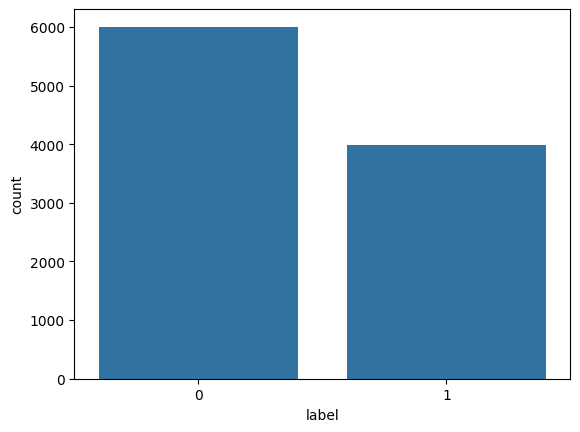

In [165]:
sns.countplot(df,x="label")
plt.show()

In [166]:
X.head()

0    outlook.com weekly report budget review statem...
1    company.com project update team sync president...
2    unknownmail.cc win big now win free urgent off...
3    chealdealz.xyz win big now guarantee click cas...
4    yahoo.com meeting reminder team sync significa...
Name: final_text, dtype: object

In [167]:
from sklearn.feature_extraction.text import TfidfVectorizer

Tfidf_vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1,2))

X_train_1 = Tfidf_vectorizer.fit_transform(X_train)
X_test_1 = Tfidf_vectorizer.transform(X_test)

In [168]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import AdaBoostClassifier,StackingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score,f1_score

In [169]:
model_mnb = MultinomialNB(alpha=1.5)
model_mnb.fit(X_train_1,y_train)
y_p = model_mnb.predict(X_test_1)
accuracy_score(y_p,y_test)

1.0

In [170]:
models = {
    "LR":LogisticRegression(class_weight="balanced"),
    "KNN":KNeighborsClassifier(n_neighbors=1),
    "DT":DecisionTreeClassifier(splitter="random",class_weight="balanced"),
    "XB":XGBClassifier(),
    "AB":AdaBoostClassifier(learning_rate=0.1),
    "MB":MultinomialNB()
}
for name,model in models.items():
    model.fit(X_train_1,y_train)
    y_pred = model.predict(X_test_1)
    print(name,(f"ACC : {accuracy_score(y_pred,y_test)} F1 : {f1_score(y_pred,y_test)}"))

LR ACC : 1.0 F1 : 1.0
KNN ACC : 1.0 F1 : 1.0
DT ACC : 1.0 F1 : 1.0
XB ACC : 1.0 F1 : 1.0
AB ACC : 1.0 F1 : 1.0
MB ACC : 1.0 F1 : 1.0


In [171]:
estimators = [
    ('LR', LogisticRegression()),
    ('MB',MultinomialNB()),
    ('DT',DecisionTreeClassifier())
]
Stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=KNeighborsClassifier(n_neighbors=1),
    cv=5
)
Stacking.fit(X_train_1,y_train)
y_pred = Stacking.predict(X_test_1)
accuracy_score(y_pred,y_test)

1.0

In [172]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1201
           1       1.00      1.00      1.00       799

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [173]:
out = ['win big now win free urgent offer limited limited urgent urgent free beyond baby physical environmental none meeting foreign low unknownmail.cc']

X_input_m = Tfidf_vectorizer.transform(out)

prediction = model_mnb.predict(X_input_m)

if prediction[0] == 1:
    print("Result: Spam")
else:
    print("Result: Not Spam")

Result: Spam


In [174]:
from sklearn.pipeline import Pipeline

model_pipeline = Pipeline([
    ("tfidf",Tfidf_vectorizer),
    ("model",MultinomialNB())
])

model_pipeline.fit(X_train,y_train)
y_pred = model_pipeline.predict(X_test)
accuracy_score(y_pred,y_test)

1.0

In [175]:
stacking_pipeline = Pipeline([
    ("tfidf",Tfidf_vectorizer),
    ("model",StackingClassifier(
        estimators=estimators,
        final_estimator=KNeighborsClassifier(n_neighbors=1),
        cv=5
    ))
])

model_pipeline.fit(X_train,y_train)
y_pred = model_pipeline.predict(X_test)
accuracy_score(y_pred,y_test)

1.0

In [176]:
from joblib import dump
dump(model_pipeline,'model_pipeline.pkl')
dump(stacking_pipeline,'stacking_pipeline.pkl')
dump(Tfidf_vectorizer,'vectorizer.pkl')

['vectorizer.pkl']